# 03 - Weather EDA & Weather-Usage Relationships (BijliCast)

**CT-378 Phase 2: EDA - step 3**

Covers **weather distributions**, **correlations** (weather vs usage) and the
**autocorrelation** that motivates the autoregressive (lag) features.
Produces 4 plots.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Locate repo root (works whether run from notebooks/ or repo root)
ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)
print("Figures  :", FIG)

df = pd.read_parquet(ROOT / "data" / "processed" / "hourly_combined.parquet")
df["datetime"] = pd.to_datetime(df["datetime"])
print("Dataset:", df.shape)
df.head()

Repo root: D:\BijliCast
Figures  : D:\BijliCast\reports\figures


Dataset: (515786, 12)


,datetime,usage_kw,house_id,city,temperature,humidity,dew,precipitation,wind_speed,wind_direction,pressure,solar_radiation
0,2023-11-01 00:00:00,0.525333,House#41,Islamabad,17.9,75,13.5,0.0,5.2,344,957.3,0.0
1,2023-11-01 01:00:00,0.560500,House#41,Islamabad,18.2,72,13.2,0.0,6.2,339,957.3,0.0
2,2023-11-01 02:00:00,0.593833,House#41,Islamabad,18.6,70,13.1,0.0,5.0,330,957.3,0.0
3,2023-11-01 03:00:00,0.587667,House#41,Islamabad,19.3,67,13.1,0.0,3.7,331,957.4,0.0
4,2023-11-01 04:00:00,0.594000,House#41,Islamabad,17.9,74,13.2,0.0,3.9,326,957.1,0.0


## 1. Weather feature summary

In [2]:
wx = ["temperature","humidity","dew","precipitation","wind_speed","wind_direction","pressure","solar_radiation"]
df[wx].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
temperature,515786.0,21.64,10.07,-10.4,14.3,23.0,29.3,47.0
humidity,515786.0,59.98,22.11,5.0,43.0,61.0,78.0,100.0
dew,515786.0,12.21,9.73,-23.4,6.4,11.9,21.1,28.7
precipitation,515786.0,0.09,0.58,0.0,0.0,0.0,0.0,19.9
wind_speed,515786.0,8.32,6.11,0.0,4.0,6.7,10.6,46.6
wind_direction,515786.0,206.61,111.68,1.0,101.0,236.0,306.0,360.0
pressure,515786.0,949.81,75.58,761.6,951.7,978.7,994.5,1023.4
solar_radiation,515786.0,202.63,274.06,0.0,0.0,10.0,400.0,1090.0


### Plot 7 - Weather feature distributions

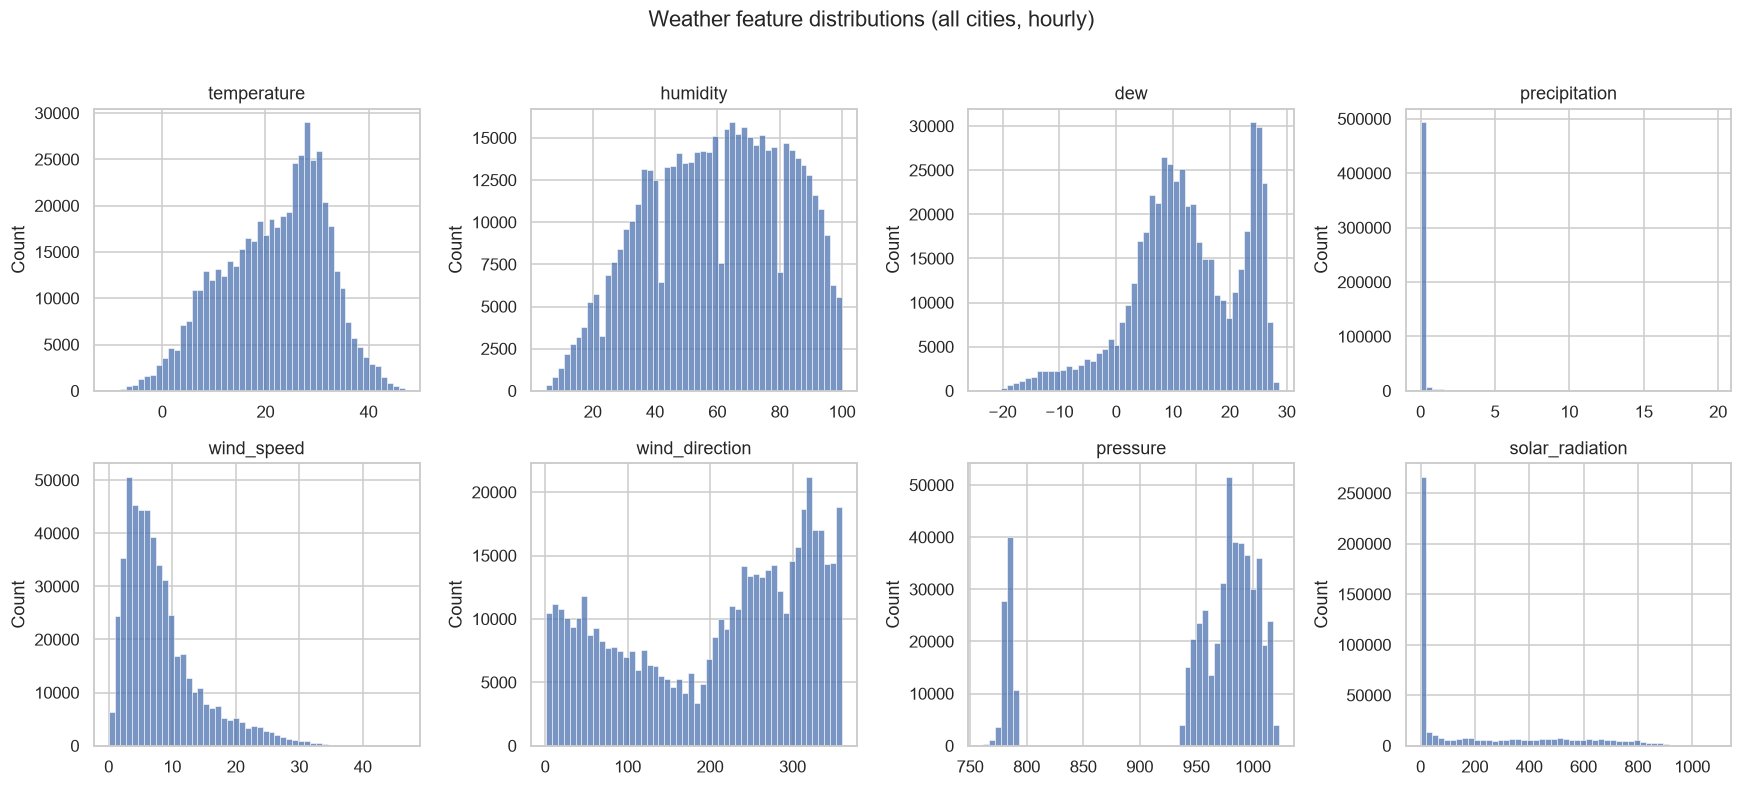

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), wx):
    sns.histplot(df[c].dropna(), bins=50, ax=ax, color="#4c72b0")
    ax.set_title(c)
    ax.set_xlabel("")
plt.suptitle("Weather feature distributions (all cities, hourly)", y=1.02)
plt.tight_layout()
plt.savefig(FIG / "03_weather_distributions.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 8 - Temperature vs usage by city

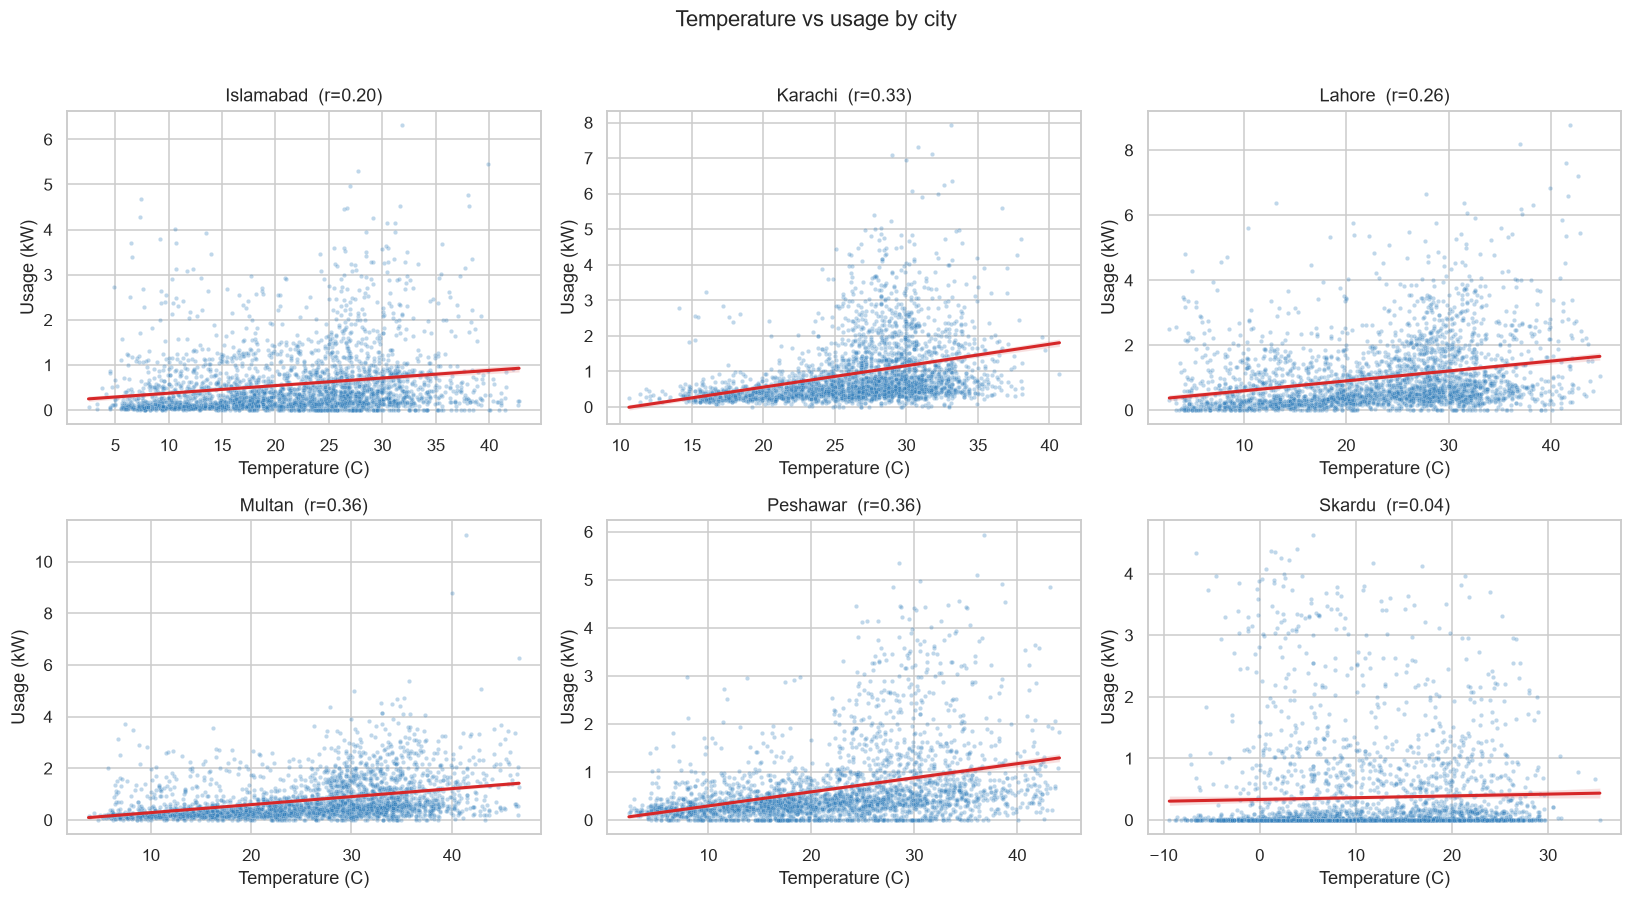

In [4]:
cities = sorted(df["city"].unique())
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), cities):
    full = df[df["city"] == c][["temperature", "usage_kw"]].dropna()
    d = full.sample(min(len(full), 3000), random_state=0)
    sns.scatterplot(data=d, x="temperature", y="usage_kw", ax=ax, s=8, alpha=0.3, color="#2b7bba")
    if len(d) > 2:
        sns.regplot(data=d, x="temperature", y="usage_kw", ax=ax, scatter=False, color="#d62728", line_kws={"lw": 2})
    r = full.corr().iloc[0, 1] if len(full) > 2 else np.nan
    ax.set_title(f"{c}  (r={r:.2f})")
    ax.set_xlabel("Temperature (C)")
    ax.set_ylabel("Usage (kW)")
plt.suptitle("Temperature vs usage by city", y=1.02)
plt.tight_layout()
plt.savefig(FIG / "03_temp_vs_usage_by_city.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 9 - Correlation matrix (usage vs weather)

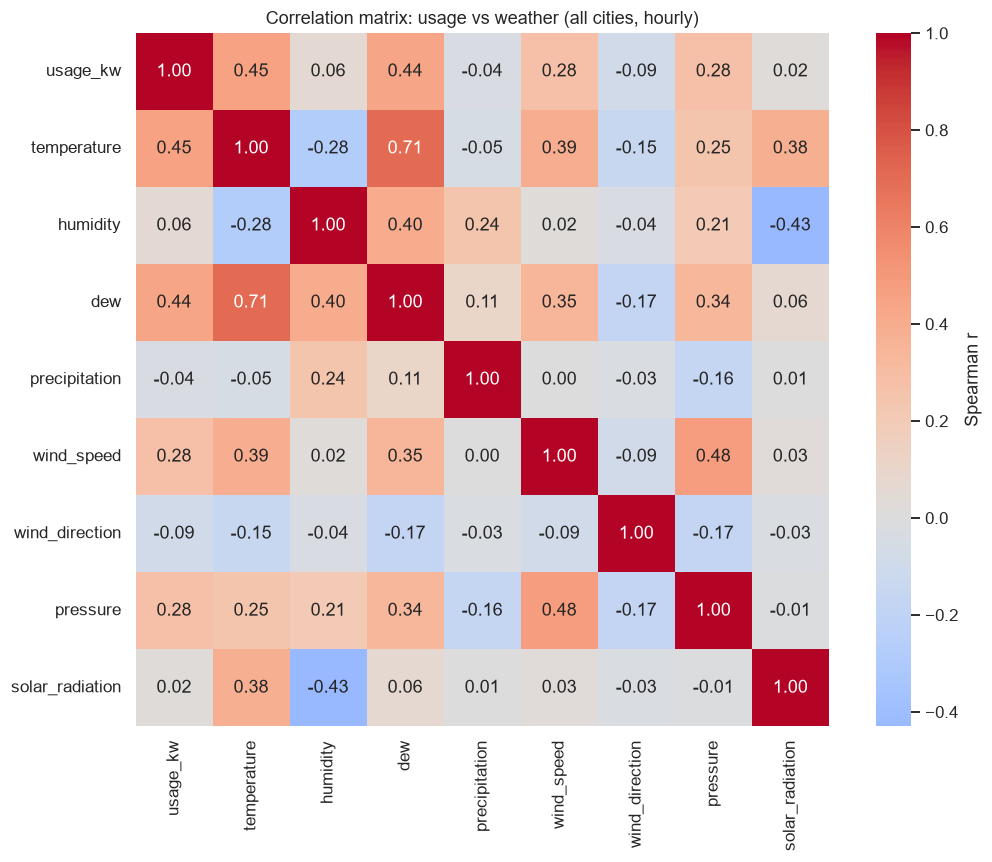

In [5]:
corr_cols = ["usage_kw"] + wx
corr = df[corr_cols].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"label": "Spearman r"})
plt.title("Correlation matrix: usage vs weather (all cities, hourly)")
plt.tight_layout()
plt.savefig(FIG / "03_correlation_matrix.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 10 - Usage autocorrelation by lag (motivates lag features)

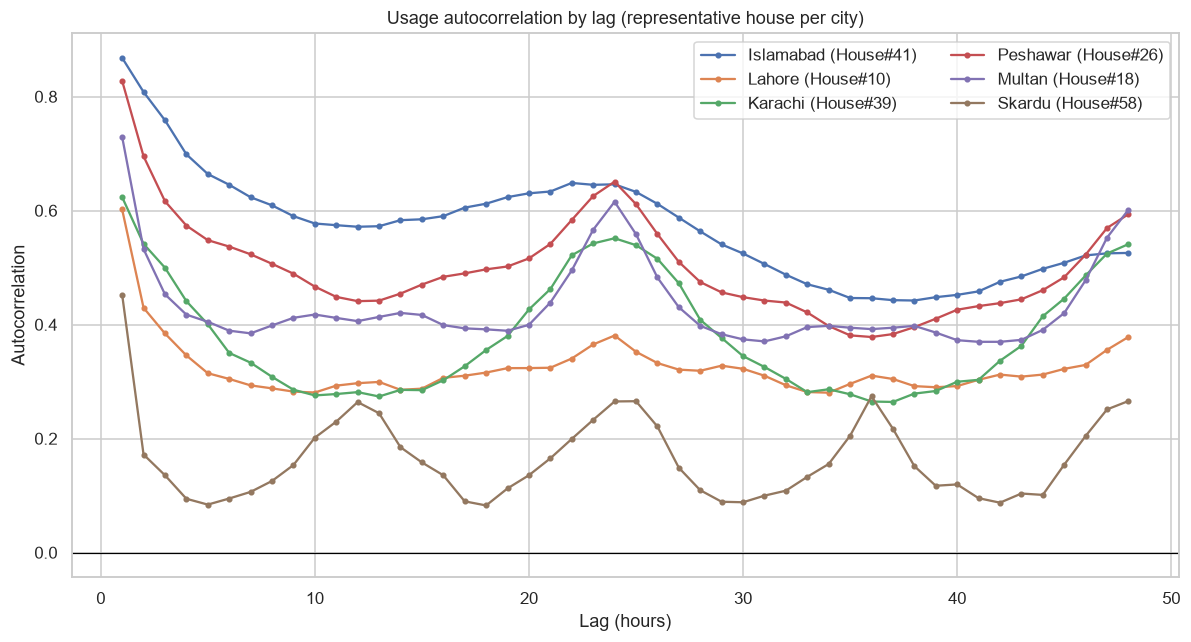

In [6]:
lags = list(range(1, 49))
rep = df.groupby(["city", "house_id"])["usage_kw"].apply(lambda s: s.notna().mean()).reset_index(name="valid")
rep = rep.sort_values("valid", ascending=False).groupby("city").head(1)
plt.figure(figsize=(11, 6))
for _, row in rep.iterrows():
    s = df[(df["city"] == row["city"]) & (df["house_id"] == row["house_id"])].sort_values("datetime")["usage_kw"].reset_index(drop=True)
    ac = [s.autocorr(lag=l) for l in lags]
    plt.plot(lags, ac, marker="o", ms=3, label=f"{row['city']} ({row['house_id']})")
plt.axhline(0, color="black", lw=0.8)
plt.title("Usage autocorrelation by lag (representative house per city)")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig(FIG / "03_usage_autocorrelation.png", dpi=220, bbox_inches="tight")
plt.show()

## Findings - Notebook 03

- Weather features are well-behaved; **temperature** dominates the relationship with usage, with strong positive correlation in hot cities (e.g. Karachi) and weaker/different shapes in cold, high-altitude Skardu.
- The **correlation matrix** quantifies which weather variables matter most and confirms multicollinearity (dew/temperature/humidity).
- **Autocorrelation** is high at short lags and decays with a 24-hour cycle - exactly why the plan includes lag (1h/2h/3h/24h/168h) and rolling-window features.

### EDA requirements coverage (CT-378)
| Requirement | Where |
|---|---|
| Distributions | Plots 1, 4, 7 |
| Missing values | Plot 2 |
| Outliers | Plot 5 |
| Correlations | Plots 8, 9, 10 |
| Class/target balance | Plot 6 |
| >= 5 plots | 10 plots saved to `reports/figures/` |